# Dataset B — PlainMLP v1 evidence dashboard (PMLP-00 → PMLP-05)

Notebook này lưu lịch sử thực thi **PMLP-01/02** và cung cấp dashboard chỉ đọc cho toàn bộ bằng chứng PMLP-00 đến PMLP-05. Production execution nằm trong các runner `.py`; notebook không phải nơi chạy lại training, Validation prediction hoặc Test evaluation.

Ranh giới bắt buộc:

- dashboard chỉ đọc frozen artifact; không mở lại raw Validation/Test partition;
- không fit lại preprocessing trong notebook này;
- không gọi production runner, không chọn lại threshold và không predict lại;
- configuration vẫn là `provisional_starting_configuration`, không phải project default/final;
- kết quả chỉ được ghi atomically sau khi toàn bộ năm fold và OOF gates đều pass.

Saved evidence gồm PMLP-00 preprocessing, PMLP-01 CV/OOF, PMLP-02 configuration decision, PMLP-03 fresh full-Train bundle, PMLP-04A/B Validation prediction và threshold lock, cùng PMLP-05 Test/RQ1 evaluation. Chuỗi PlainMLP đã `COMPLETE` trong phạm vi `temporary_training_lock_v0_2`; final feature lock vẫn chưa thay đổi. Source YAML vẫn provisional và bất biến; configuration của run được khóa trong decision artifact riêng.

## Historical execution — PMLP-01 (không chạy lại)

Các cell bên dưới là provenance của lần chạy PMLP-01 đã công bố. Chúng chứa training và publication logic lịch sử, được giữ nguyên để audit; **không Run All và không chạy lại các cell này**. Dashboard chỉ đọc bắt đầu tại mục `Read-only evidence dashboard` ở cuối notebook.

In [1]:
from __future__ import annotations

import hashlib
import json
import math
import platform
import shutil
import tempfile
import time
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import yaml
from scipy.sparse import isspmatrix_csr, load_npz
from sklearn.metrics import roc_auc_score
import sys
PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "config/dataset_b/model_protocol_v1.yaml").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate the Dataset B project root.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.dataset_b.models.plain_mlp import PlainMLPClassifier
from src.utils.path import PROJECT_ROOT

CONFIG_PATH = PROJECT_ROOT / 'config' / 'dataset_b' / 'plain_mlp_v1.yaml'
CV_ARTIFACT_DIR = (
    PROJECT_ROOT / 'data' / 'preprocessing' / 'dataset_b_v1'
    / 'cv_neural_preprocessing_v1'
)
MANIFEST_PATH = CV_ARTIFACT_DIR / 'manifest.json'
RESULT_DIR = PROJECT_ROOT / 'artifacts' / 'dataset_b' / 'plain_mlp_v1'
WRAPPER_PATH = PROJECT_ROOT / 'src' / 'dataset_b' / 'models' / 'plain_mlp.py'
OUTPUT_NAMES = (
    'cv_results.json',
    'cv_oof_predictions.csv',
    'cv_training_history.json',
)

In [2]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def require(condition: bool, message: str) -> None:
    if not condition:
        raise ValueError(message)


config = yaml.safe_load(CONFIG_PATH.read_text(encoding='utf-8'))
manifest = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))

require(config['model_version'] == 'plain_mlp_v1', 'Unexpected plain MLP model version.')
require(
    config['status'] == 'provisional_starting_configuration',
    'PMLP-01 requires the provisional starting configuration.',
)
require(config['is_project_default'] is False, 'PMLP-01 cannot use a project-default flag.')
require(config['is_final_configuration'] is False, 'PMLP-01 cannot use a final flag.')
require(config['selected_by_train_cv'] is False, 'PMLP-01 cannot pre-claim CV selection.')
require(config['environment']['device'] == 'cpu', 'plain_mlp_v1 is locked to CPU.')
require(config['environment']['torch_build'] == 'cpu', 'A CPU-only PyTorch build is required.')
require(not torch.cuda.is_available(), 'PMLP-01 must not silently switch to a GPU runtime.')
require(
    platform.python_version() == config['environment']['python_version'],
    'Python version differs from the locked neural environment.',
)
require(
    version('torch').split('+', maxsplit=1)[0] == str(config['environment']['torch_release']),
    'PyTorch release differs from the locked neural environment.',
)

require(manifest['source_partition'] == 'train', 'Neural CV artifact is not Train-only.')
require(manifest['fit_scope'] == 'fold_train_only', 'Unexpected preprocessing fit scope.')
require(manifest['use'] == 'cross_validation_only', 'Artifact is not marked CV-only.')
require(manifest['fold_count'] == 5, 'PMLP-01 requires exactly five folds.')
require(manifest['matrix_count'] == 10, 'PMLP-01 requires ten fold matrices.')
require(manifest['encoded_feature_count'] == 66, 'Expected the locked 66-column input width.')
require(manifest['matrix_format'] == 'csr', 'Expected CSR fold matrices.')
require(manifest['matrix_dtype'] == 'float32', 'Expected float32 fold matrices.')
require(
    manifest['preprocessing_version'] == config['contracts']['preprocessing_version'],
    'Preprocessing version differs between config and artifact.',
)
require(
    manifest['source_hashes']['plain_mlp_config']['sha256'] == sha256_file(CONFIG_PATH),
    'The PMLP config changed after preprocessing export.',
)

if RESULT_DIR.exists():
    raise FileExistsError(f'PMLP-01 refuses to overwrite an existing result directory: {RESULT_DIR}')

for relative_path, expected_hash in manifest['artifact_hashes'].items():
    artifact_path = CV_ARTIFACT_DIR / relative_path
    require(artifact_path.is_file(), f'Missing neural CV artifact: {relative_path}')
    require(sha256_file(artifact_path) == expected_hash, f'Hash mismatch: {relative_path}')

ValueError: The PMLP config changed after preprocessing export.

In [ ]:
fold_inputs: list[dict[str, object]] = []
fold_entries = sorted(manifest['folds'], key=lambda item: item['fold'])
require([entry['fold'] for entry in fold_entries] == [1, 2, 3, 4, 5], 'Invalid fold numbering.')
n_train = sum(int(entry['fold_validation_rows']) for entry in fold_entries)
require(n_train > 0, 'The Train partition is empty.')

oof_record_ids = np.empty(n_train, dtype=object)
oof_labels = np.full(n_train, -1, dtype=np.int8)
oof_fold = np.zeros(n_train, dtype=np.int8)
coverage = np.zeros(n_train, dtype=np.int8)

for entry in fold_entries:
    fold_number = int(entry['fold'])
    fold_dir = CV_ARTIFACT_DIR / str(entry['directory'])
    rows_path = fold_dir / 'rows.npz'
    with np.load(rows_path, allow_pickle=False) as rows:
        train_positions = rows['train_positions'].astype(np.int64, copy=False)
        validation_positions = rows['fold_validation_positions'].astype(np.int64, copy=False)
        train_record_ids = rows['train_record_ids'].astype(str, copy=False)
        validation_record_ids = rows['fold_validation_record_ids'].astype(str, copy=False)
        train_y = rows['train_y'].astype(np.int8, copy=False)
        validation_y = rows['fold_validation_y'].astype(np.int8, copy=False)

    require(len(train_positions) == int(entry['train_rows']), f'Fold {fold_number}: train row mismatch.')
    require(
        len(validation_positions) == int(entry['fold_validation_rows']),
        f'Fold {fold_number}: validation row mismatch.',
    )
    require(len(train_record_ids) == len(train_positions), f'Fold {fold_number}: train ID mismatch.')
    require(
        len(validation_record_ids) == len(validation_positions),
        f'Fold {fold_number}: validation ID mismatch.',
    )
    require(len(train_y) == len(train_positions), f'Fold {fold_number}: train label mismatch.')
    require(len(validation_y) == len(validation_positions), f'Fold {fold_number}: validation label mismatch.')
    require(set(np.unique(train_y).tolist()) == {0, 1}, f'Fold {fold_number}: train is not binary.')
    require(set(np.unique(validation_y).tolist()) == {0, 1}, f'Fold {fold_number}: validation is not binary.')
    require(
        np.intersect1d(train_positions, validation_positions).size == 0,
        f'Fold {fold_number}: train/validation overlap.',
    )
    require(
        np.array_equal(
            np.sort(np.concatenate((train_positions, validation_positions))),
            np.arange(n_train),
        ),
        f'Fold {fold_number}: positions do not partition Train.',
    )
    require(np.all(coverage[validation_positions] == 0), f'Fold {fold_number}: duplicate OOF positions.')

    coverage[validation_positions] = 1
    oof_record_ids[validation_positions] = validation_record_ids
    oof_labels[validation_positions] = validation_y
    oof_fold[validation_positions] = fold_number
    fold_inputs.append(
        {
            'fold': fold_number,
            'train_matrix_path': fold_dir / 'plain_mlp_train.npz',
            'validation_matrix_path': fold_dir / 'plain_mlp_fold_validation.npz',
            'train_positions': train_positions,
            'validation_positions': validation_positions,
            'train_y': train_y,
            'validation_y': validation_y,
        }
    )

require(np.all(coverage == 1), 'Fold-validation rows do not cover Train exactly once.')
require(np.all(oof_labels >= 0), 'Some OOF labels were not assigned.')
require(np.all(oof_fold > 0), 'Some OOF fold labels were not assigned.')
require(len(set(oof_record_ids.tolist())) == n_train, 'Train record_id values are not unique.')

In [ ]:
training_config = config['training']
architecture_config = config['architecture']
class_handling = config['class_handling']
require(training_config['loss'] == 'BCEWithLogitsLoss', 'Unexpected loss contract.')
require(training_config['optimizer'] == 'AdamW', 'Unexpected optimizer contract.')
require(training_config['early_stopping'] is False, 'PMLP-01 does not use early stopping.')
require(architecture_config['activation'] == 'ReLU', 'Unexpected activation contract.')
require(architecture_config['output_units'] == 1, 'Binary plain MLP requires one output logit.')
require(
    class_handling == {
        'class_weight': False,
        'sample_weight': False,
        'resampling': False,
    },
    'PMLP-01 does not permit class weighting, sample weighting, or resampling.',
)


def make_estimator() -> PlainMLPClassifier:
    return PlainMLPClassifier(
        hidden_layers=tuple(architecture_config['hidden_layers']),
        activation=architecture_config['activation'],
        learning_rate=float(training_config['learning_rate']),
        weight_decay=float(training_config['weight_decay']),
        dropout=float(training_config['dropout']),
        batch_size=int(training_config['batch_size']),
        epochs=int(training_config['epochs']),
        random_state=int(training_config['random_state']),
        device=config['environment']['device'],
        deterministic_algorithms=bool(training_config['deterministic_algorithms']),
    )

In [ ]:
oof_probability = np.full(n_train, np.nan, dtype=np.float64)
fold_results: list[dict[str, object]] = []
fold_histories: list[dict[str, object]] = []
fitted_estimators: list[PlainMLPClassifier] = []
cv_started = time.perf_counter()

for fold_input in fold_inputs:
    fold_number = int(fold_input['fold'])
    X_train = load_npz(fold_input['train_matrix_path'])
    X_validation = load_npz(fold_input['validation_matrix_path'])
    train_y = fold_input['train_y']
    validation_y = fold_input['validation_y']
    validation_positions = fold_input['validation_positions']

    require(isspmatrix_csr(X_train), f'Fold {fold_number}: train matrix is not CSR.')
    require(isspmatrix_csr(X_validation), f'Fold {fold_number}: validation matrix is not CSR.')
    require(X_train.dtype == np.float32, f'Fold {fold_number}: train matrix is not float32.')
    require(X_validation.dtype == np.float32, f'Fold {fold_number}: validation matrix is not float32.')
    require(X_train.shape == (len(train_y), 66), f'Fold {fold_number}: train shape mismatch.')
    require(
        X_validation.shape == (len(validation_y), 66),
        f'Fold {fold_number}: validation shape mismatch.',
    )
    require(np.isfinite(X_train.data).all(), f'Fold {fold_number}: non-finite train value.')
    require(np.isfinite(X_validation.data).all(), f'Fold {fold_number}: non-finite validation value.')

    estimator = make_estimator()
    fold_started = time.perf_counter()
    estimator.fit(X_train, train_y)
    probability = estimator.predict_proba(X_validation)[:, 1]
    fold_seconds = time.perf_counter() - fold_started

    require(probability.shape == (len(validation_y),), f'Fold {fold_number}: probability shape mismatch.')
    require(np.isfinite(probability).all(), f'Fold {fold_number}: non-finite probabilities.')
    require(np.all((probability >= 0.0) & (probability <= 1.0)), f'Fold {fold_number}: invalid probability.')
    require(
        all(
            estimator.model_ is not previous.model_
            and estimator.optimizer_ is not previous.optimizer_
            for previous in fitted_estimators
        ),
        f'Fold {fold_number}: fitted model or optimizer state was reused.',
    )

    fold_auc = float(roc_auc_score(validation_y, probability))
    oof_probability[validation_positions] = probability
    fold_results.append(
        {
            'fold': fold_number,
            'train_rows': int(X_train.shape[0]),
            'fold_validation_rows': int(X_validation.shape[0]),
            'roc_auc': fold_auc,
            'runtime_seconds': float(fold_seconds),
        }
    )
    fold_histories.append(
        {
            'fold': fold_number,
            'epoch_count': len(estimator.training_history_),
            'training_loss': [float(value) for value in estimator.training_history_],
        }
    )
    fitted_estimators.append(estimator)

cv_runtime_seconds = time.perf_counter() - cv_started

In [ ]:
require(len(fold_results) == 5, 'PMLP-01 did not complete exactly five folds.')
require(np.isfinite(oof_probability).all(), 'OOF probabilities do not cover all Train rows.')
require(
    all(item['epoch_count'] == int(training_config['epochs']) for item in fold_histories),
    'A fold did not complete the locked epoch count.',
)

fold_auc_values = np.asarray([item['roc_auc'] for item in fold_results], dtype=np.float64)
oof_predictions = pd.DataFrame(
    {
        'record_id': oof_record_ids.astype(str),
        'fold': oof_fold,
        'y_approved': oof_labels,
        'p_approved': oof_probability,
    }
)
require(len(oof_predictions) == n_train, 'OOF artifact row count differs from Train.')
require(oof_predictions['record_id'].is_unique, 'OOF artifact contains duplicate record_id values.')
require(
    sorted(oof_predictions['fold'].unique().tolist()) == [1, 2, 3, 4, 5],
    'OOF artifact does not contain all five folds.',
)

source_sha256 = {
    'plain_mlp_config': {
        'path': CONFIG_PATH.relative_to(PROJECT_ROOT).as_posix(),
        'sha256': sha256_file(CONFIG_PATH),
    },
    'neural_preprocessing_manifest': {
        'path': MANIFEST_PATH.relative_to(PROJECT_ROOT).as_posix(),
        'sha256': sha256_file(MANIFEST_PATH),
    },
    'plain_mlp_wrapper': {
        'path': WRAPPER_PATH.relative_to(PROJECT_ROOT).as_posix(),
        'sha256': sha256_file(WRAPPER_PATH),
    },
}

history_payload = {
    'schema_version': 1,
    'dataset': 'dataset_b',
    'model_version': config['model_version'],
    'stage': 'train_only_cross_validation',
    'source_partition': 'train',
    'external_validation_used': False,
    'test_used': False,
    'folds': fold_histories,
}
results_payload = {
    'schema_version': 1,
    'dataset': 'dataset_b',
    'model': 'plain_mlp',
    'model_version': config['model_version'],
    'stage': 'train_only_cross_validation',
    'status': 'complete',
    'configuration_status': config['status'],
    'is_project_default': False,
    'is_final_configuration': False,
    'selected_by_train_cv': False,
    'feature_version': manifest['feature_version'],
    'split_version': manifest['split_version'],
    'preprocessing_version': manifest['preprocessing_version'],
    'source_partition': 'train',
    'fit_scope': 'fold_train_only',
    'external_validation_used': False,
    'test_used': False,
    'fold_count': 5,
    'train_rows': int(n_train),
    'encoded_feature_count': 66,
    'primary_metric': 'roc_auc',
    'roc_auc_std_ddof': 0,
    'mean_roc_auc': float(fold_auc_values.mean()),
    'std_roc_auc': float(fold_auc_values.std(ddof=0)),
    'oof_roc_auc': float(roc_auc_score(oof_labels, oof_probability)),
    'runtime_seconds': float(cv_runtime_seconds),
    'estimated_optimizer_steps': int(
        sum(math.ceil(item['train_rows'] / int(training_config['batch_size'])) for item in fold_results)
        * int(training_config['epochs'])
    ),
    'parameters': {
        'architecture': architecture_config,
        'training': training_config,
        'class_handling': class_handling,
    },
    'folds': fold_results,
    'source_sha256': source_sha256,
    'library_versions': {
        'python': platform.python_version(),
        'numpy': version('numpy'),
        'pandas': version('pandas'),
        'scikit-learn': version('scikit-learn'),
        'scipy': version('scipy'),
        'torch': version('torch'),
    },
}

In [ ]:
RESULT_DIR.parent.mkdir(parents=True, exist_ok=True)
staging_dir = Path(
    tempfile.mkdtemp(prefix=f'.{RESULT_DIR.name}.pmlp01-staging-', dir=RESULT_DIR.parent)
)
try:
    oof_path = staging_dir / 'cv_oof_predictions.csv'
    history_path = staging_dir / 'cv_training_history.json'
    results_path = staging_dir / 'cv_results.json'

    oof_predictions.to_csv(oof_path, index=False)
    history_path.write_text(
        json.dumps(history_payload, ensure_ascii=False, indent=2),
        encoding='utf-8',
    )
    results_payload['output_sha256'] = {
        oof_path.name: sha256_file(oof_path),
        history_path.name: sha256_file(history_path),
    }
    results_path.write_text(
        json.dumps(results_payload, ensure_ascii=False, indent=2),
        encoding='utf-8',
    )
    require(
        sorted(path.name for path in staging_dir.iterdir()) == sorted(OUTPUT_NAMES),
        'PMLP-01 staging directory contains an unexpected file set.',
    )
    staging_dir.replace(RESULT_DIR)
except Exception:
    if staging_dir.exists():
        shutil.rmtree(staging_dir)
    raise

{
    'result_directory': RESULT_DIR.relative_to(PROJECT_ROOT).as_posix(),
    'fold_roc_auc': [item['roc_auc'] for item in fold_results],
    'mean_roc_auc': results_payload['mean_roc_auc'],
    'std_roc_auc': results_payload['std_roc_auc'],
    'oof_rows': len(oof_predictions),
    'runtime_seconds': results_payload['runtime_seconds'],
    'configuration_status': results_payload['configuration_status'],
}

{'result_directory': 'artifacts/dataset_b/plain_mlp_v1',
 'fold_roc_auc': [0.8489262561326291,
  0.845496713562307,
  0.851838528212763,
  0.8464716584562774,
  0.8496548916280409],
 'mean_roc_auc': 0.8484776095984035,
 'std_roc_auc': 0.002271238947576423,
 'oof_rows': 205310,
 'runtime_seconds': 1637.2283279999992,
 'configuration_status': 'provisional_starting_configuration'}

## Historical execution — PMLP-02 review và configuration decision (không chạy lại)

Bước này chỉ đọc PMLP-01 artifacts và source hashes. Không mở Validation/Test, không HPO lại và không sửa đè `plain_mlp_v1.yaml`. Kết quả là một decision artifact bất biến cho phép fresh full-Train refit ở PMLP-03.

In [ ]:
PMLP01_RESULT_PATH = RESULT_DIR / 'cv_results.json'
PMLP01_OOF_PATH = RESULT_DIR / 'cv_oof_predictions.csv'
PMLP01_HISTORY_PATH = RESULT_DIR / 'cv_training_history.json'
PMLP02_SELECTION_PATH = RESULT_DIR / 'configuration_selection.json'

pmlp02_results = json.loads(PMLP01_RESULT_PATH.read_text(encoding='utf-8'))
pmlp02_history = json.loads(PMLP01_HISTORY_PATH.read_text(encoding='utf-8'))
pmlp02_oof = pd.read_csv(PMLP01_OOF_PATH, dtype={'record_id': str})

require(pmlp02_results['stage'] == 'train_only_cross_validation', 'PMLP-01 stage mismatch.')
require(pmlp02_results['status'] == 'complete', 'PMLP-01 is not complete.')
require(pmlp02_results['fold_count'] == 5, 'PMLP-01 must contain five folds.')
require(pmlp02_results['train_rows'] == 205310, 'PMLP-01 Train row count mismatch.')
require(pmlp02_results['external_validation_used'] is False, 'PMLP-01 used Validation.')
require(pmlp02_results['test_used'] is False, 'PMLP-01 used Test.')
require(pmlp02_results['configuration_status'] == 'provisional_starting_configuration', 'Source configuration status changed.')
require(pmlp02_results['selected_by_train_cv'] is False, 'PMLP-01 pre-claimed selection.')
require(len(pmlp02_oof) == 205310, 'PMLP-01 OOF row count mismatch.')
require(pmlp02_oof['record_id'].is_unique, 'PMLP-01 OOF record_id is not unique.')
require(sorted(pmlp02_oof['fold'].unique().tolist()) == [1, 2, 3, 4, 5], 'PMLP-01 OOF fold set mismatch.')
require(np.isfinite(pmlp02_oof['p_approved'].to_numpy(dtype=np.float64)).all(), 'PMLP-01 OOF contains non-finite probabilities.')
require(len(pmlp02_history['folds']) == 5, 'PMLP-01 history fold count mismatch.')
require(all(item['epoch_count'] == 100 for item in pmlp02_history['folds']), 'PMLP-01 epoch count mismatch.')
require(sha256_file(PMLP01_OOF_PATH) == pmlp02_results['output_sha256']['cv_oof_predictions.csv'], 'PMLP-01 OOF hash mismatch.')
require(sha256_file(PMLP01_HISTORY_PATH) == pmlp02_results['output_sha256']['cv_training_history.json'], 'PMLP-01 history hash mismatch.')
require(sha256_file(CONFIG_PATH) == pmlp02_results['source_sha256']['plain_mlp_config']['sha256'], 'PMLP-01 config hash mismatch.')
require(sha256_file(MANIFEST_PATH) == pmlp02_results['source_sha256']['neural_preprocessing_manifest']['sha256'], 'PMLP-01 preprocessing manifest hash mismatch.')
require(sha256_file(WRAPPER_PATH) == pmlp02_results['source_sha256']['plain_mlp_wrapper']['sha256'], 'PMLP-01 wrapper hash mismatch.')

pmlp02_selection = {
    'schema_version': 1,
    'dataset': 'dataset_b',
    'model': 'plain_mlp',
    'model_version': 'plain_mlp_v1',
    'stage': 'configuration_selection_after_train_cv',
    'status': 'complete',
    'decision': 'accept_for_full_train_refit',
    'selection_basis': 'single_fixed_phase_1_candidate_reviewed_on_train_only_cv',
    'candidate_count': 1,
    'hyperparameter_search_performed': False,
    'selected_for_run': True,
    'is_project_default': False,
    'is_final_configuration_for_run': True,
    'source_configuration_status': pmlp02_results['configuration_status'],
    'feature_version': pmlp02_results['feature_version'],
    'split_version': pmlp02_results['split_version'],
    'preprocessing_version': pmlp02_results['preprocessing_version'],
    'external_validation_used': False,
    'test_used': False,
    'reviewed_cv_metrics': {
        'primary_metric': pmlp02_results['primary_metric'],
        'mean_roc_auc': pmlp02_results['mean_roc_auc'],
        'std_roc_auc': pmlp02_results['std_roc_auc'],
        'oof_roc_auc': pmlp02_results['oof_roc_auc'],
        'fold_roc_auc': [item['roc_auc'] for item in pmlp02_results['folds']],
    },
    'locked_configuration': pmlp02_results['parameters'],
    'source_sha256': {
        'plain_mlp_config': sha256_file(CONFIG_PATH),
        'neural_preprocessing_manifest': sha256_file(MANIFEST_PATH),
        'plain_mlp_wrapper': sha256_file(WRAPPER_PATH),
        'cv_results': sha256_file(PMLP01_RESULT_PATH),
        'cv_oof_predictions': sha256_file(PMLP01_OOF_PATH),
        'cv_training_history': sha256_file(PMLP01_HISTORY_PATH),
    },
}
pmlp02_bytes = (json.dumps(pmlp02_selection, ensure_ascii=False, indent=2) + '\n').encode('utf-8')
if PMLP02_SELECTION_PATH.exists():
    require(PMLP02_SELECTION_PATH.read_bytes() == pmlp02_bytes, 'Existing PMLP-02 decision differs; refusing to overwrite.')
else:
    pmlp02_temp = PMLP02_SELECTION_PATH.with_name('.configuration_selection.json.tmp')
    pmlp02_temp.write_bytes(pmlp02_bytes)
    pmlp02_temp.replace(PMLP02_SELECTION_PATH)

{
    'decision': pmlp02_selection['decision'],
    'selected_for_run': pmlp02_selection['selected_for_run'],
    'mean_roc_auc': pmlp02_selection['reviewed_cv_metrics']['mean_roc_auc'],
    'selection_artifact': PMLP02_SELECTION_PATH.relative_to(PROJECT_ROOT).as_posix(),
}

# Read-only evidence dashboard — PMLP-00 đến PMLP-05

Phần này là checkpoint trực quan, không phải production runner. Các cell chỉ đọc artifact đã công bố, kiểm tra hash và vẽ biểu đồ; không gọi `fit`, `fit_transform`, `predict_proba`, không mở raw Validation/Test partition và không ghi vào thư mục artifact. Chỉ chạy riêng phần dashboard này từ trên xuống; **không Run All** vì các cell training phía trên là historical execution.

In [3]:
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from html import escape
from IPython.display import Markdown, SVG, display

DASHBOARD_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'artifacts/dataset_b/plain_mlp_v1/cv_results.json').is_file()),
    None,
)
if DASHBOARD_ROOT is None:
    raise FileNotFoundError('Cannot locate PlainMLP artifacts from the current working directory.')

PMLP_DIR = DASHBOARD_ROOT / 'artifacts/dataset_b/plain_mlp_v1'
PMLP00_DIR = DASHBOARD_ROOT / 'data/preprocessing/dataset_b_v1/cv_neural_preprocessing_v1'
FULL_TRAIN_DIR = PMLP_DIR / 'full_train'
VALIDATION_DIR = PMLP_DIR / 'validation'
THRESHOLD_DIR = VALIDATION_DIR / 'threshold_selection'
TEST_DIR = PMLP_DIR / 'test_evaluation'

def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding='utf-8'))

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

pmlp00_manifest = read_json(PMLP00_DIR / 'manifest.json')
cv_results = read_json(PMLP_DIR / 'cv_results.json')
cv_history = read_json(PMLP_DIR / 'cv_training_history.json')
selection = read_json(PMLP_DIR / 'configuration_selection.json')
full_train_manifest = read_json(FULL_TRAIN_DIR / 'manifest.json')
full_train_result = read_json(FULL_TRAIN_DIR / 'full_train_result.json')
full_train_bundle = joblib.load(FULL_TRAIN_DIR / 'checkpoints/fitted_bundle.joblib')
full_train_history = np.asarray(
    full_train_bundle['model_checkpoint']['training_history'], dtype=np.float64
)
validation_manifest = read_json(VALIDATION_DIR / 'run_manifest.json')
validation_result = read_json(VALIDATION_DIR / 'validation_result.json')
validation_predictions = pd.read_csv(VALIDATION_DIR / 'validation_predictions.csv', dtype={'record_id': str})
threshold_manifest = read_json(THRESHOLD_DIR / 'threshold_manifest.json')
threshold_selection = read_json(THRESHOLD_DIR / 'threshold_selection.json')
threshold_candidates = pd.read_csv(THRESHOLD_DIR / 'threshold_candidates.csv')
test_manifest = read_json(TEST_DIR / 'run_manifest.json')
test_result = read_json(TEST_DIR / 'rq1_test_metrics.json')
test_predictions = pd.read_csv(TEST_DIR / 'test_predictions.csv', dtype={'record_id': str})
bootstrap_metrics = pd.read_csv(TEST_DIR / 'rq1_bootstrap_metrics.csv')

def line_chart_svg(series: list[tuple[str, np.ndarray, str]], title: str, y_label: str) -> SVG:
    width, height = 920, 420
    left, right, top, bottom = 75, 25, 55, 62
    plot_w, plot_h = width - left - right, height - top - bottom
    all_values = np.concatenate([values for _, values, _ in series])
    y_min, y_max = float(all_values.min()), float(all_values.max())
    padding = max((y_max - y_min) * 0.08, 1e-6)
    y_min, y_max = y_min - padding, y_max + padding
    def x_pos(index: int, count: int) -> float:
        return left + (index / max(count - 1, 1)) * plot_w
    def y_pos(value: float) -> float:
        return top + (y_max - value) / (y_max - y_min) * plot_h
    svg = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
           '<rect width="100%" height="100%" fill="white"/>',
           f'<text x="{left}" y="28" font-family="Arial" font-size="18" fill="#263238">{escape(title)}</text>']
    for tick in range(5):
        value = y_min + tick * (y_max - y_min) / 4
        y = y_pos(value)
        svg += [f'<line x1="{left}" y1="{y:.1f}" x2="{left + plot_w}" y2="{y:.1f}" stroke="#E0E0E0"/>',
                f'<text x="{left - 9}" y="{y + 4:.1f}" text-anchor="end" font-family="Arial" font-size="11" fill="#546E7A">{value:.3f}</text>']
    svg += [f'<line x1="{left}" y1="{top}" x2="{left}" y2="{top + plot_h}" stroke="#455A64"/>',
            f'<line x1="{left}" y1="{top + plot_h}" x2="{left + plot_w}" y2="{top + plot_h}" stroke="#455A64"/>']
    for label, values, color in series:
        points = ' '.join(f'{x_pos(i, len(values)):.1f},{y_pos(float(value)):.1f}' for i, value in enumerate(values))
        svg.append(f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2"/>')
    max_count = max(len(values) for _, values, _ in series)
    for epoch in (1, 20, 40, 60, 80, max_count):
        x = x_pos(epoch - 1, max_count)
        svg.append(f'<text x="{x:.1f}" y="{top + plot_h + 22}" text-anchor="middle" font-family="Arial" font-size="11" fill="#546E7A">{epoch}</text>')
    svg += [f'<text x="{left + plot_w / 2:.1f}" y="{height - 12}" text-anchor="middle" font-family="Arial" font-size="12" fill="#37474F">Epoch</text>',
            f'<text transform="translate(17 {top + plot_h / 2:.1f}) rotate(-90)" text-anchor="middle" font-family="Arial" font-size="12" fill="#37474F">{escape(y_label)}</text>']
    legend_x = left + 8
    for index, (label, _, color) in enumerate(series):
        x = legend_x + index * 140
        svg += [f'<line x1="{x}" y1="43" x2="{x + 22}" y2="43" stroke="{color}" stroke-width="3"/>',
                f'<text x="{x + 28}" y="47" font-family="Arial" font-size="11" fill="#37474F">{escape(label)}</text>']
    svg.append('</svg>')
    return SVG(''.join(svg))

stage_status = pd.DataFrame([
    ('PMLP-00', 'COMPLETE', 'Train-only fold preprocessing', '5 folds / 10 CSR matrices / 66 columns'),
    ('PMLP-01', 'COMPLETE', 'Train-only CV + OOF', '5 folds / 205,310 OOF rows'),
    ('PMLP-02', 'COMPLETE', 'Configuration decision', selection['decision']),
    ('PMLP-03', 'COMPLETE', 'Fresh full-Train fit', 'Frozen bundle; reload consistency PASS'),
    ('PMLP-04A', 'COMPLETE', 'Frozen Validation prediction', '43,995 ordered rows; no fit'),
    ('PMLP-04B', 'COMPLETE', 'Validation threshold lock', f"threshold={threshold_selection['selected_threshold']:.3f}; 999 candidates"),
    ('PMLP-05', 'COMPLETE', 'Test/RQ1 evaluation', '43,996 ordered rows; 1,000 shared bootstrap replicates'),
], columns=['Stage', 'Status', 'Scope', 'Evidence'])
display(Markdown('**Overall PlainMLP status: COMPLETE within `temporary_training_lock_v0_2`** — final feature lock remains pending.'))
display(stage_status.style.hide(axis='index'))

locked_configuration = pd.json_normalize(selection['locked_configuration'], sep='.').T.reset_index()
locked_configuration.columns = ['Parameter', 'Locked value']
display(Markdown('### Configuration locked by PMLP-02 decision artifact'))
display(locked_configuration.style.hide(axis='index'))


**Overall PlainMLP status: COMPLETE within `temporary_training_lock_v0_2`** — final feature lock remains pending.

Stage,Status,Scope,Evidence
PMLP-00,COMPLETE,Train-only fold preprocessing,5 folds / 10 CSR matrices / 66 columns
PMLP-01,COMPLETE,Train-only CV + OOF,"5 folds / 205,310 OOF rows"
PMLP-02,COMPLETE,Configuration decision,accept_for_full_train_refit
PMLP-03,COMPLETE,Fresh full-Train fit,Frozen bundle; reload consistency PASS
PMLP-04A,COMPLETE,Frozen Validation prediction,"43,995 ordered rows; no fit"
PMLP-04B,COMPLETE,Validation threshold lock,threshold=0.738; 999 candidates
PMLP-05,COMPLETE,Test/RQ1 evaluation,"43,996 ordered rows; 1,000 shared bootstrap replicates"


### Configuration locked by PMLP-02 decision artifact

Parameter,Locked value
architecture.hidden_layers,"[128, 64]"
architecture.activation,ReLU
architecture.output_units,1
training.loss,BCEWithLogitsLoss
training.optimizer,AdamW
training.learning_rate,0.001000
training.weight_decay,0.000100
training.dropout,0.100000
training.batch_size,256
training.epochs,100


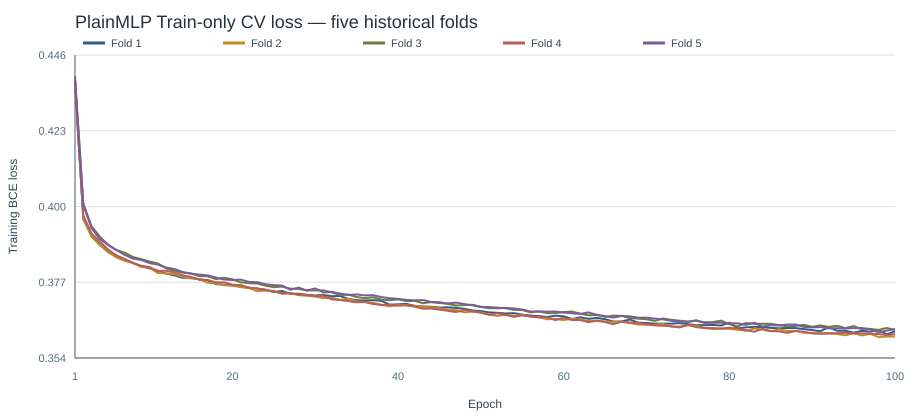

In [4]:
palette = ['#2F5D8A', '#C68A22', '#6B7D3D', '#B85C5C', '#7A5C99']
cv_loss_series = [
    (f"Fold {fold_item['fold']}", np.asarray(fold_item['training_loss'], dtype=np.float64), color)
    for fold_item, color in zip(cv_history['folds'], palette)
]
display(line_chart_svg(cv_loss_series, 'PlainMLP Train-only CV loss — five historical folds', 'Training BCE loss'))


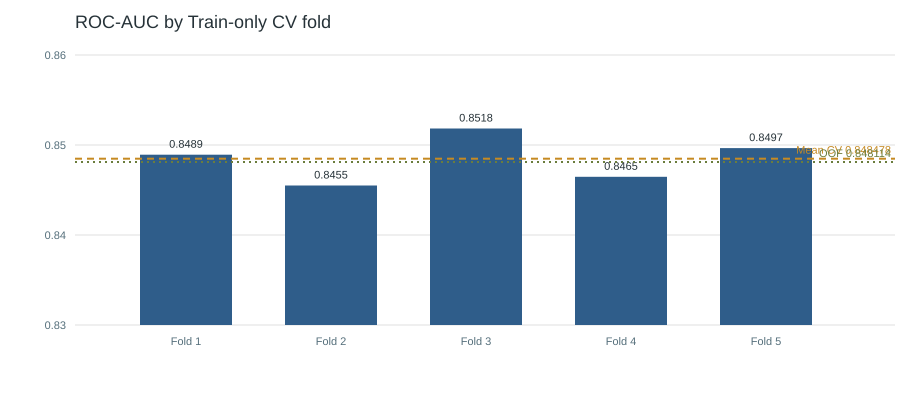

Metric,Value
Mean fold ROC-AUC,0.8484776096
Fold ROC-AUC std (ddof=0),0.0022712389
OOF ROC-AUC,0.8481142379


In [5]:
fold_auc = pd.DataFrame(cv_results['folds'])[['fold', 'roc_auc']]
auc_min, auc_max = 0.83, 0.86
width, height, left, top, plot_w, plot_h = 920, 400, 75, 55, 820, 270
svg = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
       '<rect width="100%" height="100%" fill="white"/>',
       '<text x="75" y="28" font-family="Arial" font-size="18" fill="#263238">ROC-AUC by Train-only CV fold</text>']
def auc_y(value: float) -> float:
    return top + (auc_max - value) / (auc_max - auc_min) * plot_h
for tick in np.linspace(auc_min, auc_max, 4):
    y = auc_y(float(tick))
    svg += [f'<line x1="{left}" y1="{y:.1f}" x2="{left + plot_w}" y2="{y:.1f}" stroke="#E0E0E0"/>',
            f'<text x="{left - 9}" y="{y + 4:.1f}" text-anchor="end" font-family="Arial" font-size="11" fill="#546E7A">{tick:.2f}</text>']
bar_w = 92
for index, row in fold_auc.iterrows():
    x = left + 65 + index * 145
    y = auc_y(float(row['roc_auc']))
    svg += [f'<rect x="{x}" y="{y:.1f}" width="{bar_w}" height="{top + plot_h - y:.1f}" fill="#2F5D8A"/>',
            f'<text x="{x + bar_w / 2:.1f}" y="{y - 7:.1f}" text-anchor="middle" font-family="Arial" font-size="11" fill="#263238">{row["roc_auc"]:.4f}</text>',
            f'<text x="{x + bar_w / 2:.1f}" y="{top + plot_h + 20}" text-anchor="middle" font-family="Arial" font-size="11" fill="#546E7A">Fold {int(row["fold"])}</text>']
for value, color, label, dash in [(cv_results['mean_roc_auc'], '#C68A22', 'Mean CV', '7 5'), (cv_results['oof_roc_auc'], '#6B7D3D', 'OOF', '2 4')]:
    y = auc_y(float(value))
    svg += [f'<line x1="{left}" y1="{y:.1f}" x2="{left + plot_w}" y2="{y:.1f}" stroke="{color}" stroke-width="2" stroke-dasharray="{dash}"/>',
            f'<text x="{left + plot_w - 4}" y="{y - 5:.1f}" text-anchor="end" font-family="Arial" font-size="11" fill="{color}">{label} {value:.6f}</text>']
svg.append('</svg>')
display(SVG(''.join(svg)))
display(pd.DataFrame({
    'Metric': ['Mean fold ROC-AUC', 'Fold ROC-AUC std (ddof=0)', 'OOF ROC-AUC'],
    'Value': [cv_results['mean_roc_auc'], cv_results['std_roc_auc'], cv_results['oof_roc_auc']],
}).style.format({'Value': '{:.10f}'}).hide(axis='index'))


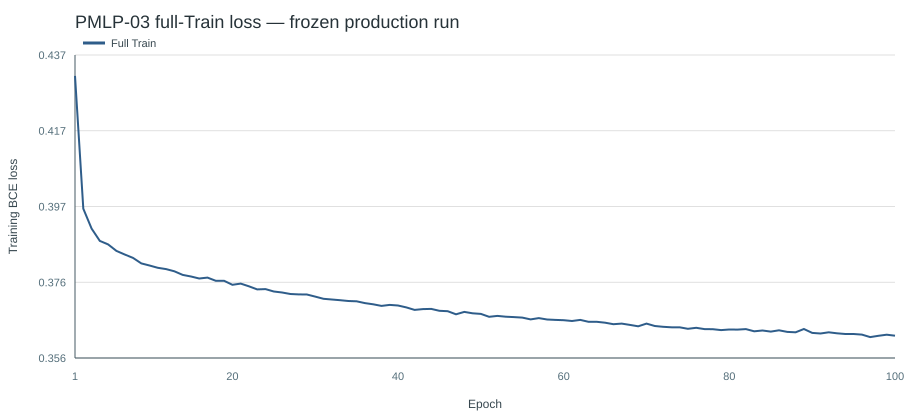

100 epochs; loss starts at **0.4317** and ends at **0.3620**.

In [6]:
display(line_chart_svg(
    [('Full Train', full_train_history, '#2F5D8A')],
    'PMLP-03 full-Train loss — frozen production run',
    'Training BCE loss',
))
display(Markdown(
    f"100 epochs; loss starts at **{full_train_history[0]:.4f}** and ends at **{full_train_history[-1]:.4f}**."
))


In [9]:
scope_table = pd.DataFrame([
    ('PMLP-01 CV', 'Fold-train only', '5 × 164,248', '5 × 41,062 fold-validation', False, False),
    ('PMLP-03 full-Train', 'Full Train only', '205,310', 'None during fitting', False, False),
], columns=['Stage', 'Fit population', 'Fit rows', 'Prediction scope', 'External Validation used', 'Test used'])
display(Markdown('### CV versus full-Train scope'))
display(scope_table.style.hide(axis='index'))

runtime_table = pd.DataFrame([
    ('PMLP-01 CV', cv_results['runtime_seconds'], cv_results['library_versions']['python'],
     cv_results['library_versions']['torch'], 'cpu'),
    ('PMLP-03 full-Train', full_train_result['execution']['elapsed_seconds'],
     full_train_result['runtime']['python'], full_train_result['runtime']['torch'],
     full_train_result['runtime']['device']),
], columns=['Stage', 'Elapsed seconds', 'Python', 'PyTorch', 'Device'])
display(Markdown('### Timing and runtime environment'))
display(runtime_table.style.format({'Elapsed seconds': '{:,.3f}'}).hide(axis='index'))

matrix_table = pd.DataFrame([
    ('PMLP-00 fold-train', '5 matrices', '164,248 × 66 each', pmlp00_manifest['matrix_format'], pmlp00_manifest['matrix_dtype'], True),
    ('PMLP-00 fold-validation', '5 matrices', '41,062 × 66 each', pmlp00_manifest['matrix_format'], pmlp00_manifest['matrix_dtype'], True),
    ('PMLP-03 full-Train', '1 fitted transform',
     f"{full_train_result['matrix']['rows']:,} × {full_train_result['matrix']['columns']}",
     full_train_result['matrix']['format'], full_train_result['matrix']['dtype'],
     full_train_result['matrix']['finite']),
], columns=['Evidence', 'Count', 'Shape', 'Format', 'Dtype', 'Finite'])
display(Markdown('### Matrix contract'))
display(matrix_table.style.hide(axis='index'))


### CV versus full-Train scope

Stage,Fit population,Fit rows,Prediction scope,External Validation used,Test used
PMLP-01 CV,Fold-train only,"5 × 164,248","5 × 41,062 fold-validation",False,False
PMLP-03 full-Train,Full Train only,"205,310",None during fitting,False,False


### Timing and runtime environment

Stage,Elapsed seconds,Python,PyTorch,Device
PMLP-01 CV,"1,637.228",3.12.13,2.14.0+cpu,cpu
PMLP-03 full-Train,447.049,3.12.13,2.14.0+cpu,cpu


### Matrix contract

Evidence,Count,Shape,Format,Dtype,Finite
PMLP-00 fold-train,5 matrices,"164,248 × 66 each",csr,float32,True
PMLP-00 fold-validation,5 matrices,"41,062 × 66 each",csr,float32,True
PMLP-03 full-Train,1 fitted transform,"205,310 × 66",csr,float32,True


In [10]:
pmlp00_hash_ok = all(
    sha256_file(PMLP00_DIR / relative_path) == expected_hash
    for relative_path, expected_hash in pmlp00_manifest['artifact_hashes'].items()
)
selection_sources = {
    'plain_mlp_config': DASHBOARD_ROOT / 'config/dataset_b/plain_mlp_v1.yaml',
    'neural_preprocessing_manifest': PMLP00_DIR / 'manifest.json',
    'plain_mlp_wrapper': DASHBOARD_ROOT / 'src/dataset_b/models/plain_mlp.py',
    'cv_results': PMLP_DIR / 'cv_results.json',
    'cv_oof_predictions': PMLP_DIR / 'cv_oof_predictions.csv',
    'cv_training_history': PMLP_DIR / 'cv_training_history.json',
}
pmlp02_source_checks = {
    name: {
        'Path': selection_sources[name].relative_to(DASHBOARD_ROOT).as_posix(),
        'Expected SHA-256': expected_hash,
        'Actual SHA-256': sha256_file(selection_sources[name]),
    }
    for name, expected_hash in selection['source_sha256'].items()
}
pmlp02_source_drift = pd.DataFrame([
    (name, item['Path'], item['Expected SHA-256'], item['Actual SHA-256'])
    for name, item in pmlp02_source_checks.items()
    if item['Actual SHA-256'] != item['Expected SHA-256']
], columns=['Source', 'Path', 'Expected SHA-256', 'Actual SHA-256'])
pmlp02_hash_ok = pmlp02_source_drift.empty
pmlp03_hash_ok = all(
    sha256_file(FULL_TRAIN_DIR / relative_path) == expected_hash
    for relative_path, expected_hash in full_train_manifest['artifact_sha256'].items()
)
validation_hash_ok = all(
    sha256_file(VALIDATION_DIR / relative_path) == expected_hash
    for relative_path, expected_hash in validation_manifest['artifact_sha256'].items()
)
threshold_hash_ok = all(
    sha256_file(THRESHOLD_DIR / relative_path) == expected_hash
    for relative_path, expected_hash in threshold_manifest['artifact_sha256'].items()
)
test_hash_ok = all(
    sha256_file(TEST_DIR / relative_path) == expected_hash
    for relative_path, expected_hash in test_manifest['artifact_sha256'].items()
)
markers_ok = {
    'PMLP-03': (FULL_TRAIN_DIR / 'COMPLETED').read_text(encoding='utf-8') == 'PMLP-03 PASS\n',
    'PMLP-04A': (VALIDATION_DIR / 'COMPLETED').read_text(encoding='utf-8') == 'PMLP-04A PASS\n',
    'PMLP-04B': (THRESHOLD_DIR / 'COMPLETED').read_text(encoding='utf-8') == 'PMLP-04B PASS\n',
    'PMLP-05': (TEST_DIR / 'COMPLETED').read_text(encoding='utf-8') == 'PMLP-05 PASS\n',
}
scope = full_train_bundle['scope']
artifact_checks = pd.DataFrame([
    ('PMLP-00 payload hashes', len(pmlp00_manifest['artifact_hashes']), pmlp00_hash_ok),
    ('PMLP-03 payload hashes', len(full_train_manifest['artifact_sha256']), pmlp03_hash_ok),
    ('PMLP-04A payload hashes', len(validation_manifest['artifact_sha256']), validation_hash_ok),
    ('PMLP-04B payload hashes', len(threshold_manifest['artifact_sha256']), threshold_hash_ok),
    ('PMLP-05 payload hashes', len(test_manifest['artifact_sha256']), test_hash_ok),
    ('PMLP-03 → PMLP-05 completion markers', len(markers_ok), all(markers_ok.values())),
    ('PMLP-03 reload prediction consistency', full_train_result['execution']['reload_prediction_rows'],
     full_train_result['execution']['reload_predictions_identical']),
    ('PMLP-03 protected partitions closed', 2,
     not scope['validation_accessed'] and not scope['test_accessed']),
    ('PMLP-04A ordered unique Validation rows', len(validation_predictions),
     len(validation_predictions) == 43_995 and validation_predictions['record_id'].is_unique),
    ('PMLP-04B frozen candidate grid', len(threshold_candidates),
     len(threshold_candidates) == 999 and threshold_selection['selected_threshold'] == 0.738),
    ('PMLP-05 ordered unique Test rows', len(test_predictions),
     len(test_predictions) == 43_996 and test_predictions['record_id'].is_unique),
    ('PMLP-05 shared bootstrap replicates', len(bootstrap_metrics),
     len(bootstrap_metrics) == 1_000 and (bootstrap_metrics['invalid_metrics'] == '{}').all()),
], columns=['Check', 'Items / rows', 'Pass'])
display(Markdown('### Lineage and artifact validation'))
display(artifact_checks.style.hide(axis='index'))
if pmlp02_hash_ok:
    display(Markdown('**PMLP-02 source lineage: PASS**'))
else:
    display(Markdown(
        '> ⚠️ **Non-blocking source drift:** one or more current source files differ '
        'from the frozen PMLP-02 lineage. Published artifact integrity checks remain blocking.'
    ))
    display(pmlp02_source_drift.style.hide(axis='index'))

lineage_table = pd.DataFrame([
    (stage, item, digest)
    for stage, lineage in [
        ('PMLP-03', full_train_result['lineage_sha256']),
        ('PMLP-04A', validation_result['lineage_sha256']),
        ('PMLP-05', test_result['lineage_sha256']),
    ]
    for item, digest in sorted(lineage.items())
], columns=['Stage', 'Lineage item', 'SHA-256'])
display(lineage_table.style.hide(axis='index'))
assert artifact_checks['Pass'].all(), 'One or more required published artifact checks failed.'


### Lineage and artifact validation

Check,Items / rows,Pass
PMLP-00 payload hashes,15,True
PMLP-03 payload hashes,2,True
PMLP-04A payload hashes,2,True
PMLP-04B payload hashes,2,True
PMLP-05 payload hashes,3,True
PMLP-03 → PMLP-05 completion markers,4,True
PMLP-03 reload prediction consistency,256,True
PMLP-03 protected partitions closed,2,True
PMLP-04A ordered unique Validation rows,43995,True
PMLP-04B frozen candidate grid,999,True


> ⚠️ **Non-blocking source drift:** one or more current source files differ from the frozen PMLP-02 lineage. Published artifact integrity checks remain blocking.

Source,Path,Expected SHA-256,Actual SHA-256
plain_mlp_wrapper,src/dataset_b/models/plain_mlp.py,20f60705e3707c27bc349a2b87a3a7afd66a2b59052a979708ff87037aa4ae7d,718c2e61319bc1a5d4ddde138b4b7295593e806c10db71ecac46e1c7959d5da2


Stage,Lineage item,SHA-256
PMLP-03,configuration_selection_sha256,62386ab560540b0c913055f8d5ad36a238b8d5efb43dc768f4af9920b761efcf
PMLP-03,feature_contract_sha256,b6d72c229b256ceff889d5bc650ea748ce2d25f151210149e1c7ed55c7c078fb
PMLP-03,plain_mlp_config_sha256,0c7747642259457683b401e1c6cc3608b968b159827468c0a59574d21262219f
PMLP-03,split_manifest_sha256,66816ba47da64bfd85c010a90a14b9d80443a46d319258bf9fc1b3657f731596
PMLP-03,train_record_ids_sha256,6898c180536d38feb3ccfdbf83fe0d26d5cdb775b0f063eed646e36b76c4c09a
PMLP-03,train_source_sha256,8c5246953453fda4282d48b09ed1e924402d17dc6c7551a6a0574c346fad51f6
PMLP-04A,feature_contract_sha256,b6d72c229b256ceff889d5bc650ea748ce2d25f151210149e1c7ed55c7c078fb
PMLP-04A,fitted_bundle_sha256,8b1019cd6cba1b27ed040ca50ba089323138f7e804b9efbaf2afd209e7adb85e
PMLP-04A,full_train_manifest_sha256,3c22478337eba9f171893a53cbc601d78beb87834c61c0a00ac40c8984baa5d6
PMLP-04A,full_train_result_sha256,eb57b6ef09390565b0a7b79c0225ba0c6ec26c2eaf1b22150522899ecde79d70


## Frozen downstream evidence — PMLP-04A, PMLP-04B và PMLP-05

Các cell dưới đây chỉ trực quan hóa Validation/Test artifacts đã đóng băng. Chúng không mở raw partition CSV, không load fitted model, không gọi production runner, không chọn lại threshold và không predict lại.

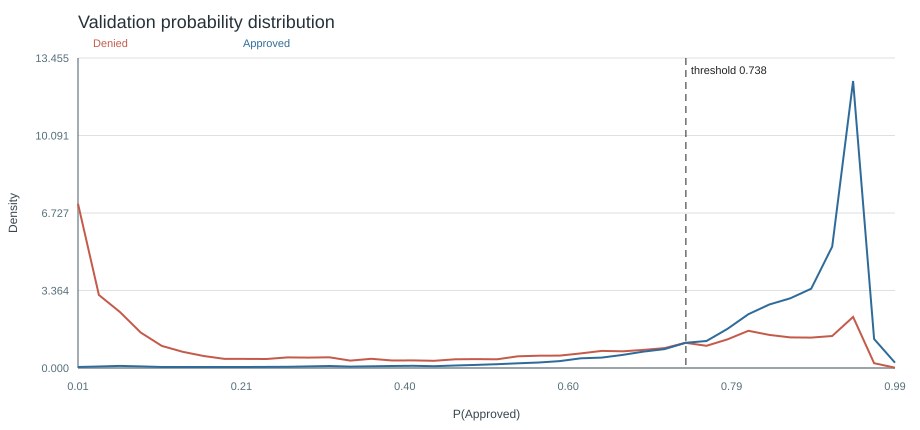

Validation class,Rows,Share
Denied,"11,181",25.41%
Approved,"32,814",74.59%


In [11]:
def xy_chart_svg(series, title, x_label, y_label, vertical_line=None):
    width, height, left, right, top, bottom = 920, 430, 78, 25, 58, 62
    plot_w, plot_h = width - left - right, height - top - bottom
    all_x = np.concatenate([np.asarray(item[1], dtype=float) for item in series])
    all_y = np.concatenate([np.asarray(item[2], dtype=float) for item in series])
    x_min, x_max = float(all_x.min()), float(all_x.max())
    y_min, y_max = min(0.0, float(all_y.min())), float(all_y.max())
    y_max += max((y_max - y_min) * 0.08, 1e-9)
    def x_pos(value): return left + (float(value) - x_min) / max(x_max - x_min, 1e-12) * plot_w
    def y_pos(value): return top + (y_max - float(value)) / max(y_max - y_min, 1e-12) * plot_h
    svg = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
           '<rect width="100%" height="100%" fill="white"/>',
           f'<text x="{left}" y="28" font-family="Arial" font-size="18" fill="#263238">{escape(title)}</text>']
    for tick in range(6):
        value = x_min + tick * (x_max - x_min) / 5
        x = x_pos(value)
        svg.append(f'<text x="{x:.1f}" y="{top + plot_h + 22}" text-anchor="middle" font-family="Arial" font-size="11" fill="#546E7A">{value:.2f}</text>')
    for tick in range(5):
        value = y_min + tick * (y_max - y_min) / 4
        y = y_pos(value)
        svg += [f'<line x1="{left}" y1="{y:.1f}" x2="{left + plot_w}" y2="{y:.1f}" stroke="#E0E0E0"/>',
                f'<text x="{left - 9}" y="{y + 4:.1f}" text-anchor="end" font-family="Arial" font-size="11" fill="#546E7A">{value:.3f}</text>']
    svg += [f'<line x1="{left}" y1="{top}" x2="{left}" y2="{top + plot_h}" stroke="#455A64"/>',
            f'<line x1="{left}" y1="{top + plot_h}" x2="{left + plot_w}" y2="{top + plot_h}" stroke="#455A64"/>']
    for index, (label, xs, ys, color) in enumerate(series):
        points = ' '.join(f'{x_pos(x):.1f},{y_pos(y):.1f}' for x, y in zip(xs, ys))
        svg += [f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2"/>',
                f'<text x="{left + 15 + index * 150}" y="47" font-family="Arial" font-size="11" fill="{color}">{escape(label)}</text>']
    if vertical_line is not None:
        value, label = vertical_line
        x = x_pos(value)
        svg += [f'<line x1="{x:.1f}" y1="{top}" x2="{x:.1f}" y2="{top + plot_h}" stroke="#222222" stroke-dasharray="7 5"/>',
                f'<text x="{x + 5:.1f}" y="{top + 16}" font-family="Arial" font-size="11" fill="#222222">{escape(label)}</text>']
    svg += [f'<text x="{left + plot_w / 2:.1f}" y="{height - 12}" text-anchor="middle" font-family="Arial" font-size="12" fill="#37474F">{escape(x_label)}</text>',
            f'<text transform="translate(17 {top + plot_h / 2:.1f}) rotate(-90)" text-anchor="middle" font-family="Arial" font-size="12" fill="#37474F">{escape(y_label)}</text>', '</svg>']
    return SVG(''.join(svg))

assert validation_result['status'] == 'PASS' and len(validation_predictions) == 43_995
validation_counts = validation_predictions['y_approved'].value_counts().sort_index()
histogram_series = []
for label, name, color in [(0, 'Denied', '#C45A4A'), (1, 'Approved', '#2F6B9A')]:
    values = validation_predictions.loc[validation_predictions['y_approved'] == label, 'p_approved']
    density, edges = np.histogram(values, bins=np.linspace(0, 1, 41), density=True)
    histogram_series.append((name, (edges[:-1] + edges[1:]) / 2, density, color))
display(xy_chart_svg(histogram_series, 'Validation probability distribution',
                     'P(Approved)', 'Density',
                     (threshold_selection['selected_threshold'], f"threshold {threshold_selection['selected_threshold']:.3f}")))
display(pd.DataFrame([
    ('Denied', int(validation_counts[0]), validation_counts[0] / len(validation_predictions)),
    ('Approved', int(validation_counts[1]), validation_counts[1] / len(validation_predictions)),
], columns=['Validation class', 'Rows', 'Share']).style.format({'Rows': '{:,}', 'Share': '{:.2%}'}).hide(axis='index'))


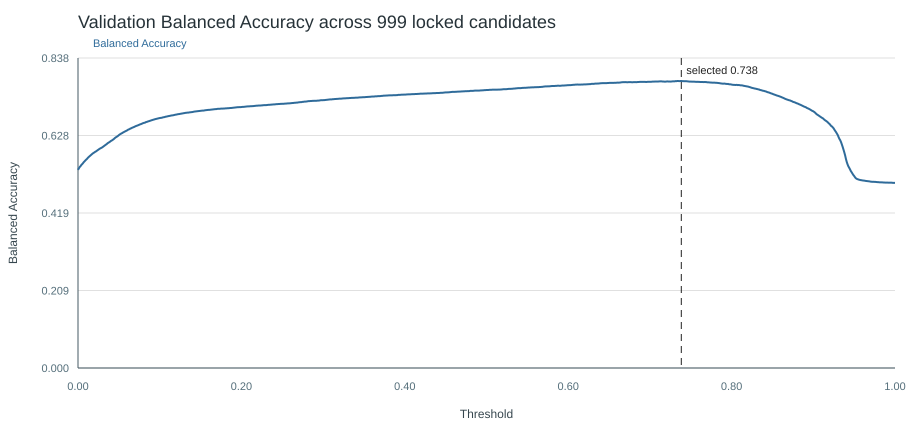

Threshold evidence,Value
Objective,maximize_validation_balanced_accuracy
Selected threshold,0.738000
Maximizer count,1
Tie-break 1,minimum_absolute_distance_to_0.5
Tie-break 2,lower_threshold


In [12]:
selected_threshold = float(threshold_selection['selected_threshold'])
selected_row = threshold_candidates.loc[
    np.isclose(threshold_candidates['threshold'], selected_threshold, rtol=0.0, atol=1e-12)
].iloc[0]
display(xy_chart_svg([
    ('Balanced Accuracy', threshold_candidates['threshold'].to_numpy(),
     threshold_candidates['balanced_accuracy'].to_numpy(), '#2F6B9A'),
], 'Validation Balanced Accuracy across 999 locked candidates', 'Threshold',
   'Balanced Accuracy', (selected_threshold, f'selected {selected_threshold:.3f}')))
display(pd.DataFrame([
    ('Objective', threshold_selection['objective']),
    ('Selected threshold', selected_threshold),
    ('Maximizer count', threshold_selection['maximizer_count']),
    ('Tie-break 1', threshold_selection['tie_break'][0]),
    ('Tie-break 2', threshold_selection['tie_break'][1]),
], columns=['Threshold evidence', 'Value']).style.hide(axis='index'))


### Test point metrics and shared-bootstrap percentile intervals

Metric,Point estimate,CI lower 2.5%,CI upper 97.5%,Valid replicates,Invalid replicates
ROC-AUC Approved,0.849485,0.844714,0.853647,1000,0
PR-AUC/AP Denied,0.761585,0.755655,0.767496,1000,0
Precision Denied,0.612068,0.605271,0.618581,1000,0
Recall Denied,0.693140,0.684641,0.701637,1000,0
F1 Denied,0.650086,0.643677,0.655943,1000,0
Recall Approved,0.850312,0.846655,0.854091,1000,0
Balanced Accuracy,0.771726,0.766887,0.776186,1000,0
Brier Approved,0.111771,0.110044,0.113414,1000,0
Calibration intercept,0.093636,0.074674,0.111605,1000,0
Calibration slope,0.952573,0.932156,0.972888,1000,0


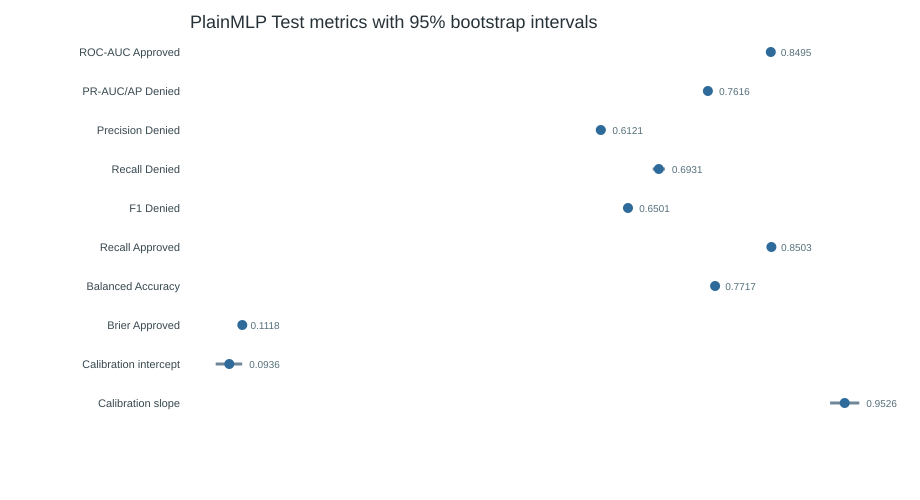

In [13]:
metric_labels = {
    'roc_auc_approved': 'ROC-AUC Approved',
    'average_precision_denied': 'PR-AUC/AP Denied',
    'precision_denied': 'Precision Denied',
    'recall_denied': 'Recall Denied',
    'f1_denied': 'F1 Denied',
    'recall_approved': 'Recall Approved',
    'balanced_accuracy': 'Balanced Accuracy',
    'brier_approved': 'Brier Approved',
    'calibration_intercept': 'Calibration intercept',
    'calibration_slope': 'Calibration slope',
}
metric_rows = []
for key, label in metric_labels.items():
    point = float(test_result['point_metrics'][key])
    interval = test_result['confidence_intervals_95_percentile'][key]
    metric_rows.append((label, point, interval['lower_2_5'], interval['upper_97_5'],
                        interval['valid_replicates'], interval['invalid_replicates']))
metric_table = pd.DataFrame(metric_rows, columns=[
    'Metric', 'Point estimate', 'CI lower 2.5%', 'CI upper 97.5%', 'Valid replicates', 'Invalid replicates'
])
display(Markdown('### Test point metrics and shared-bootstrap percentile intervals'))
display(metric_table.style.format({
    'Point estimate': '{:.6f}', 'CI lower 2.5%': '{:.6f}', 'CI upper 97.5%': '{:.6f}'
}).hide(axis='index'))
width, height, left, right, top, row_h = 920, 500, 190, 35, 52, 39
plot_w = width - left - right
x_min = float(metric_table['CI lower 2.5%'].min())
x_max = float(metric_table['CI upper 97.5%'].max())
x_pad = max((x_max - x_min) * 0.04, 1e-6)
x_min, x_max = x_min - x_pad, x_max + x_pad
def metric_x(value): return left + (float(value) - x_min) / (x_max - x_min) * plot_w
svg = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
       '<rect width="100%" height="100%" fill="white"/>',
       f'<text x="{left}" y="28" font-family="Arial" font-size="18" fill="#263238">PlainMLP Test metrics with 95% bootstrap intervals</text>']
for index, row in metric_table.iterrows():
    y = top + index * row_h
    low, point, high = row['CI lower 2.5%'], row['Point estimate'], row['CI upper 97.5%']
    svg += [f'<text x="{left - 10}" y="{y + 4}" text-anchor="end" font-family="Arial" font-size="11" fill="#37474F">{escape(row["Metric"])}</text>',
            f'<line x1="{metric_x(low):.1f}" y1="{y}" x2="{metric_x(high):.1f}" y2="{y}" stroke="#6F8799" stroke-width="3"/>',
            f'<circle cx="{metric_x(point):.1f}" cy="{y}" r="5" fill="#2F6B9A"/>',
            f'<text x="{metric_x(high) + 7:.1f}" y="{y + 4}" font-family="Arial" font-size="10" fill="#546E7A">{point:.4f}</text>']
svg.append('</svg>')
display(SVG(''.join(svg)))


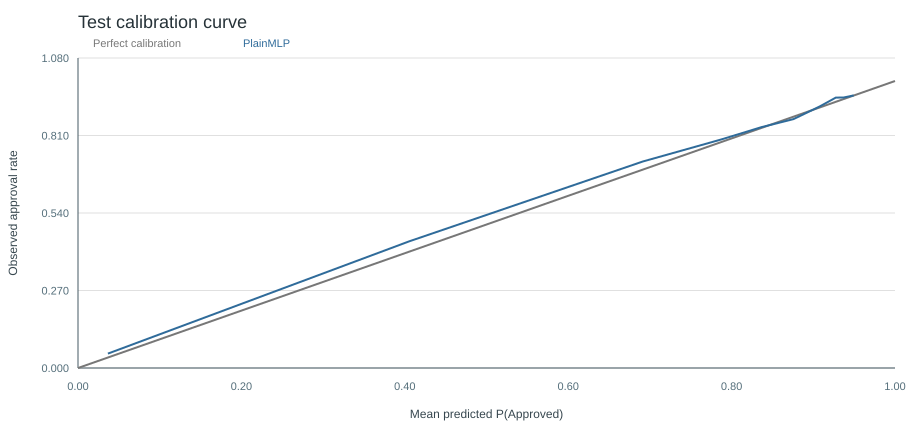

### Test confusion counts at threshold 0.738

,Predicted Denied,Predicted Approved
Actual Denied,"7,750","3,431"
Actual Approved,"4,912","27,903"


Calibration metric,Value
Calibration intercept,0.093636
Calibration slope,0.952573


In [14]:
calibration = pd.DataFrame(test_result['calibration_curve'])
counts = test_result['counts']
confusion = np.asarray([[counts['tn_denied'], counts['fp_denied']],
                        [counts['fn_approved'], counts['tp_approved']]])
display(xy_chart_svg([
    ('Perfect calibration', np.asarray([0.0, 1.0]), np.asarray([0.0, 1.0]), '#777777'),
    ('PlainMLP', calibration['mean_p_approved'].to_numpy(),
     calibration['observed_approval_rate'].to_numpy(), '#2F6B9A'),
], 'Test calibration curve', 'Mean predicted P(Approved)', 'Observed approval rate'))
confusion_table = pd.DataFrame(
    confusion, index=['Actual Denied', 'Actual Approved'],
    columns=['Predicted Denied', 'Predicted Approved']
)
display(Markdown(f"### Test confusion counts at threshold {test_result['threshold']:.3f}"))
display(confusion_table.style.format('{:,}'))
display(pd.DataFrame([
    ('Calibration intercept', test_result['point_metrics']['calibration_intercept']),
    ('Calibration slope', test_result['point_metrics']['calibration_slope']),
], columns=['Calibration metric', 'Value']).style.format({'Value': '{:.6f}'}).hide(axis='index'))


In [15]:
timing_table = pd.DataFrame([
    ('Full-Train runner', test_result['computational_metrics_seconds']['full_train_runner_elapsed']),
    ('Test preprocessing + inference',
     test_result['computational_metrics_seconds']['test_inference_including_preprocessing']),
], columns=['Operation', 'Seconds'])
boundary_table = pd.DataFrame([
    ('Model fit calls on Test', test_result['execution']['model_fit_calls']),
    ('Preprocessing fit calls on Test', test_result['execution']['preprocessing_fit_calls']),
    ('Preprocessing transform calls', test_result['execution']['preprocessing_transform_calls']),
    ('predict_proba calls', test_result['execution']['predict_proba_calls']),
    ('Threshold changed', test_result['data_boundary']['threshold_changed']),
    ('Shared bootstrap regenerated', test_result['data_boundary']['shared_bootstrap_regenerated']),
], columns=['Boundary check', 'Recorded value'])
display(Markdown('### Timing and execution boundary'))
display(timing_table.style.format({'Seconds': '{:,.4f}'}).hide(axis='index'))
display(boundary_table.style.hide(axis='index'))


### Timing and execution boundary

Operation,Seconds
Full-Train runner,447.0493
Test preprocessing + inference,0.5064


Boundary check,Recorded value
Model fit calls on Test,0
Preprocessing fit calls on Test,0
Preprocessing transform calls,1
predict_proba calls,1
Threshold changed,False
Shared bootstrap regenerated,False


## Scope conclusion

PlainMLP is end-to-end **COMPLETE** from PMLP-00 through PMLP-05 within `temporary_training_lock_v0_2`. This evidence does not create or imply a final feature lock, does not authorize a cross-model significance claim, and does not open RQ2/RQ3 prerequisites that remain unmet elsewhere.